# 复现「主要内容 2」：建立混沌振子模型 · 相轨迹演变 · 临界阈值

> 本 notebook 是 [解读文档](02-阶段二/解读-主要内容2-混沌振子建模与临界阈值.md) 的可执行部分，对应：
>
> - **index 课题要求「主要内容」第 2 条**：建立混沌振子检测模型，分析其相轨迹演变规律并确定混沌到周期态转变的临界阈值；
> - **阅读路线「阶段 2」（第 3–5 周）**：过关产出 = 单振子 RK4 仿真 + 两幅并列相图 + 可复现参数表；
> - **★[2] 母本论文** Yang Y, Ding Q, Gao Y, Chen J. *Chaotic Effect-Based Array Duffing Systems with Improved Nonlinear Restoring Force for Weak Signal Detection in Dynamic MWD*[J]. Sensors, 2023, 23(17): 7598. DOI: 10.3390/s23177598。本地全文：[文献/02_Yang_阵列Duffing_MWD_Sensors2023.pdf](文献/02_Yang_阵列Duffing_MWD_Sensors2023.pdf)。

**目录**

| 节 | 内容 | 回答什么 |
|---|---|---|
| §1 | 势函数与恢复力 | 模型为什么长这样 |
| §2 | 相量合成 + 向量化 RK4 + Poincaré 判据 | 怎么把方程跑起来 |
| §3 | 混沌态 / 大周期态的 x(t)、相图、Poincaré 截面 | 轨迹怎么变 |
| §4 | 阈值扫描、精扫、四种步长敏感性 | 临界阈值是多少、稳不稳 |
| §5 | `max|x|` 判据 vs Poincaré 判据 | 为什么不能用眼睛判态 |
| §6 | 变尺度：10 rad/s → 1 rad/s，扫 R | 极低频怎么进这个模型 |
| §7 | 三振子全相位覆盖实测 | 阈值怎么用于阵列 |
| §8 | 工作点—覆盖率—虚警率权衡 | 阈值偏一点会怎样 |
| §9 | Eq.(17) 勘误验算与灾难性相消 | 阈值当标尺的精度边界 |
| §10 | Pd–SNR、ROC、自适应阈值（chaos-CFAR 雏形） | 通往「最低可检测信噪比」 |
| §11 | 结论与边界 | 哪些结论可以写进论文 |

**如何运行**：`py -m jupyter notebook`（或 VS Code / JupyterLab 打开本文件）→ Kernel: Python 3 → Run All。本机 `py` 指向 Python 3.13，已装 numpy 2.4.6 / matplotlib 3.11 / ipykernel。所有单元已实跑一遍并保留输出，直接打开即可看图；重新 Run All 约需 1–3 分钟。图片同时另存到 `复现输出/`，方便直接放进论文。

**边界声明**：本 notebook 检验的是论文 claim 的**敏感性与可复现性**，不是「证明论文错了」。复现条件为 RK4、$h=0.02$ s、$T=400$ s、Poincaré 判据、干净高斯白噪声，与论文的 Simulink Ode4、$h=0.1$ s、带限噪声、目测相图不同；论文数据与代码未公开，第三方无法完全裁定。

In [1]:
# 环境、全局参数、绘图设置
%matplotlib inline
import math, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28

OUT = Path('复现输出')
OUT.mkdir(exist_ok=True)
FIGS = []

def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches='tight', facecolor='white')
    FIGS.append(str(p))
    plt.show()
    print('图已保存:', p)

# ---- 论文参数（★[2] Eq.2/Eq.3）----
K        = 0.5      # 阻尼
LAM0     = 0.72     # 论文预置内驱幅值（工作点）
C_TRIG   = 0.73     # 论文声称的触发合成幅值
# ---- 本复现条件（解读文档 §2.3）----
H        = 0.02     # 积分步长
T        = 400.0    # 总仿真时长
BURN     = 200.0    # 丢弃瞬态
T_FAST   = 200.0    # 大批量扫描用的短时长
BURN_FAST= 100.0
PSTD_TH  = 0.08     # Poincaré 离散度判态阈值

_START = time.time()
print('numpy', np.__version__, '| 工作目录', Path.cwd())
print(f'CONFIG: k={K}, h={H}, T={T}, burn={BURN}, 判态阈值 pstd<{PSTD_TH}')
print('全部输出目录:', OUT.resolve())

numpy 2.4.6 | 工作目录 C:\Users\22902\WorkBuddy\毕设
CONFIG: k=0.5, h=0.02, T=400.0, burn=200.0, 判态阈值 pstd<0.08
全部输出目录: C:\Users\22902\WorkBuddy\毕设\复现输出


---

## §1 模型：一个被推搡的小球

**【原文】** 标准 Holmes–Duffing：$\ddot x+k\dot x-x+x^3=\lambda\cos(\omega t)$；母本改为五次恢复力（Eq.2）：

$$\ddot x+0.5\dot x-x^3+x^5=\lambda\cos(\omega t),\qquad
V(x)=-\tfrac14x^4+\tfrac16x^6,\qquad F(x)=-\frac{dV}{dx}=x^3-x^5$$

**【推断】** 先把势函数画出来，比背方程有用：两个谷 = 两个稳定平衡点，中间一座山。推力小，球在谷间乱跳（混沌）；推力够大，球绕着两个谷外侧整圈跑（大尺度周期态）。改成五次项后阱壁更陡，论文的理由是标准 Duffing 对正弦弱信号响应不敏感。**注意这里的「放大」不是能量放大，是相变：一条边界，两种定性不同的轨道。**

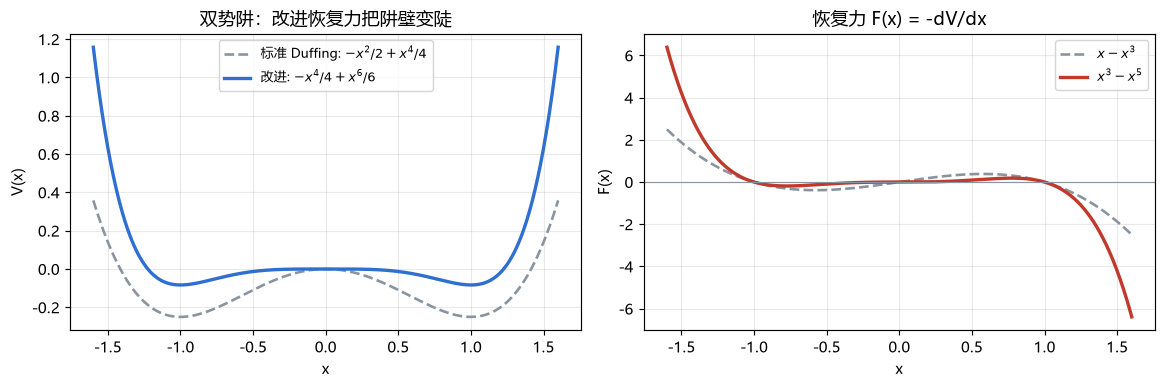

图已保存: 复现输出\fig01_势函数与恢复力.png
改进势函数: x=0 为四阶平坦的势垒顶, x=±1 为两阱底, V(±1) = -0.08333333333333334
标准势函数: x=0 为势垒顶（V″<0）, x=±1 为两阱底, V(±1) = -0.25
【推断】改进势阱更浅更窄，小球越阱所需的推力更小 —— 这是「对弱信号更敏感」的几何来源。


In [2]:
x = np.linspace(-1.6, 1.6, 800)
V5 = -x**4 / 4 + x**6 / 6          # 改进恢复力对应势函数
V3 = -x**2 / 2 + x**4 / 4          # 标准 Duffing 势函数
F5 = x**3 - x**5                    # 论文恢复力（右端移到左边后为 -F）
F3 = x - x**3

fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.8))
ax[0].plot(x, V3, '--', color='#8a94a0', lw=1.8, label=r'标准 Duffing: $-x^2/2+x^4/4$')
ax[0].plot(x, V5,      color='#2f6fd0', lw=2.3, label=r'改进: $-x^4/4+x^6/6$')
ax[0].set_title('双势阱：改进恢复力把阱壁变陡', fontsize=12)
ax[0].set_xlabel('x'); ax[0].set_ylabel('V(x)'); ax[0].legend(fontsize=9)
ax[1].plot(x, F3, '--', color='#8a94a0', lw=1.8, label=r'$x-x^3$')
ax[1].plot(x, F5,      color='#c0392b', lw=2.3, label=r'$x^3-x^5$')
ax[1].axhline(0, color='#8a94a0', lw=0.8)
ax[1].set_title('恢复力 F(x) = -dV/dx', fontsize=12)
ax[1].set_xlabel('x'); ax[1].set_ylabel('F(x)'); ax[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig01_势函数与恢复力.png')

print('改进势函数: x=0 为四阶平坦的势垒顶, x=±1 为两阱底, V(±1) =', -1/4 + 1/6)
print('标准势函数: x=0 为势垒顶（V″<0）, x=±1 为两阱底, V(±1) =', -1/2 + 1/4)
print('【推断】改进势阱更浅更窄，小球越阱所需的推力更小 —— 这是「对弱信号更敏感」的几何来源。')

---

## §2 求解器：相量合成 + 向量化 RK4 + Poincaré 判据

**【原文】** Eq.(8)–(10)：两个同频余弦合成相量

$$\lambda\cos(t+\beta)+\gamma\cos(t+\theta)=A\cos t-B\sin t,\quad
A=\lambda\cos\beta+\gamma\cos\theta,\ B=\lambda\sin\beta+\gamma\sin\theta$$
$$C^2=\lambda^2+\gamma^2+2\lambda\gamma\cos(\theta-\beta)$$

**【推断】** 这一步把「会不会相变」从动力学问题降维成比大小：$C\gtrsim 0.73$。写代码时顺手省掉一半三角函数计算；`nu != 1` 时（§6 变尺度扫描）相量合成不成立，函数自动切回双频直接积分。

**判据**：每个驱动周期 $2\pi$ 采一次 $x$，取稳态后半段这些点的标准差 $p_{std}$。周期态 → 点收敛成一个，$p_{std}\approx0.015$；混沌态 → 散成一片，$p_{std}>0.16$。**这是把「观察相图」翻译成可计算统计量的关键一步**。

噪声按 $\sigma\sqrt h\,N(0,1)$ 离散（白噪声增量是 $\sigma\,dW$，直接加 $\sigma N(0,1)$ 会让有效强度随步长变化）。

In [3]:
def simulate(lam, beta=0.0, gamma=0.0, theta=0.0, sigma=0.0, seed=0,
             h=H, t_end=T, burn=BURN, nu=1.0, trace=False):
    # 向量化 RK4：所有参数可为标量或等长数组，一次循环并行跑完一整组实验
    # nu 是待测信号与内驱的角频率比；nu=1 走 Eq.(8) 相量合成，否则双频直接积分
    lam, beta, gamma, theta, sigma = [a.ravel().astype(float).copy() for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float),
                            np.asarray(sigma, float))]
    m = lam.size
    coherent = abs(nu - 1.0) < 1e-12
    if coherent:
        A = lam * np.cos(beta) + gamma * np.cos(theta)
        B = lam * np.sin(beta) + gamma * np.sin(theta)

    x = np.zeros(m); y = np.zeros(m)
    rng = np.random.default_rng(seed)
    steps = int(round(t_end / h))
    burn_steps = int(round(burn / h))
    period_steps = max(1, int(round(2 * math.pi / h)))
    sqrt_h = math.sqrt(h)
    noisy = bool(np.any(sigma))

    poincare, mx, sq, count = [], np.zeros(m), np.zeros(m), 0
    tr_t, tr_x, tr_y = [], [], []
    for i in range(steps):
        t = i * h
        nz = rng.standard_normal(m) * sqrt_h if noisy else 0.0
        if coherent:
            f1 = A * math.cos(t)       - B * math.sin(t)       + sigma * nz
            fh = A * math.cos(t+h/2)   - B * math.sin(t+h/2)   + sigma * nz
            f4 = A * math.cos(t+h)     - B * math.sin(t+h)     + sigma * nz
        else:
            f1 = lam*np.cos(t+beta)       + gamma*np.cos(nu*t+theta)       + sigma*nz
            fh = lam*np.cos(t+h/2+beta)   + gamma*np.cos(nu*(t+h/2)+theta) + sigma*nz
            f4 = lam*np.cos(t+h+beta)     + gamma*np.cos(nu*(t+h)+theta)   + sigma*nz

        k1x = y
        k1y = -K*y + x**3 - x**5 + f1
        x2, y2 = x + h/2*k1x, y + h/2*k1y
        k2x = y2
        k2y = -K*y2 + x2**3 - x2**5 + fh
        x3, y3 = x + h/2*k2x, y + h/2*k2y
        k3x = y3
        k3y = -K*y3 + x3**3 - x3**5 + fh
        x4, y4 = x + h*k3x, y + h*k3y
        k4x = y4
        k4y = -K*y4 + x4**3 - x4**5 + f4
        x = x + h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y = y + h/6*(k1y + 2*k2y + 2*k3y + k4y)

        if i >= burn_steps:
            np.maximum(mx, np.abs(x), out=mx)
            sq += x*x
            count += 1
            if (i - burn_steps) % period_steps == 0:
                poincare.append(x.copy())
            if trace:
                tr_t.append(t); tr_x.append(x.copy()); tr_y.append(y.copy())

    p_all = np.asarray(poincare)
    p = p_all[len(p_all)//2:] if p_all.size else np.empty((0, m))
    pstd = p.std(axis=0) if p.size else np.full(m, np.nan)
    return dict(pstd=pstd, mx=mx, rms=np.sqrt(sq/max(count, 1)),
                p=p, t=np.array(tr_t) if trace else None,
                X=np.array(tr_x) if trace else None,
                Y=np.array(tr_y) if trace else None)

# 冒烟测试：论文工作点应保持混沌；推到 0.76 应进入大周期态
_r = simulate([LAM0, 0.76], seed=0)
print('冒烟测试 pstd:', np.round(_r['pstd'], 4),
      '-> 判态:', ['周期' if v < PSTD_TH else '混沌' for v in _r['pstd']])

冒烟测试 pstd: [0.4841 0.0149] -> 判态: ['混沌', '周期']


---

## §3 相轨迹演变规律（阶段 2 的过关产出）

**【推断】** 这里一次性把三样东西画出来：$x(t)$ 时序、$(x,\dot x)$ 相图、Poincaré 截面散点。前两幅是阅读路线要求的「两幅并列相图 + 时序图」，第三幅是把「变化」变成数字的证据。

盯着 Poincaré 那一列看：混沌态点铺满一个区间，周期态点收成一条水平线——**判态阈值 0.08 就画在这两团之间**。

Poincaré 离散度 pstd: {0.7: 0.5176, 0.76: 0.0149}


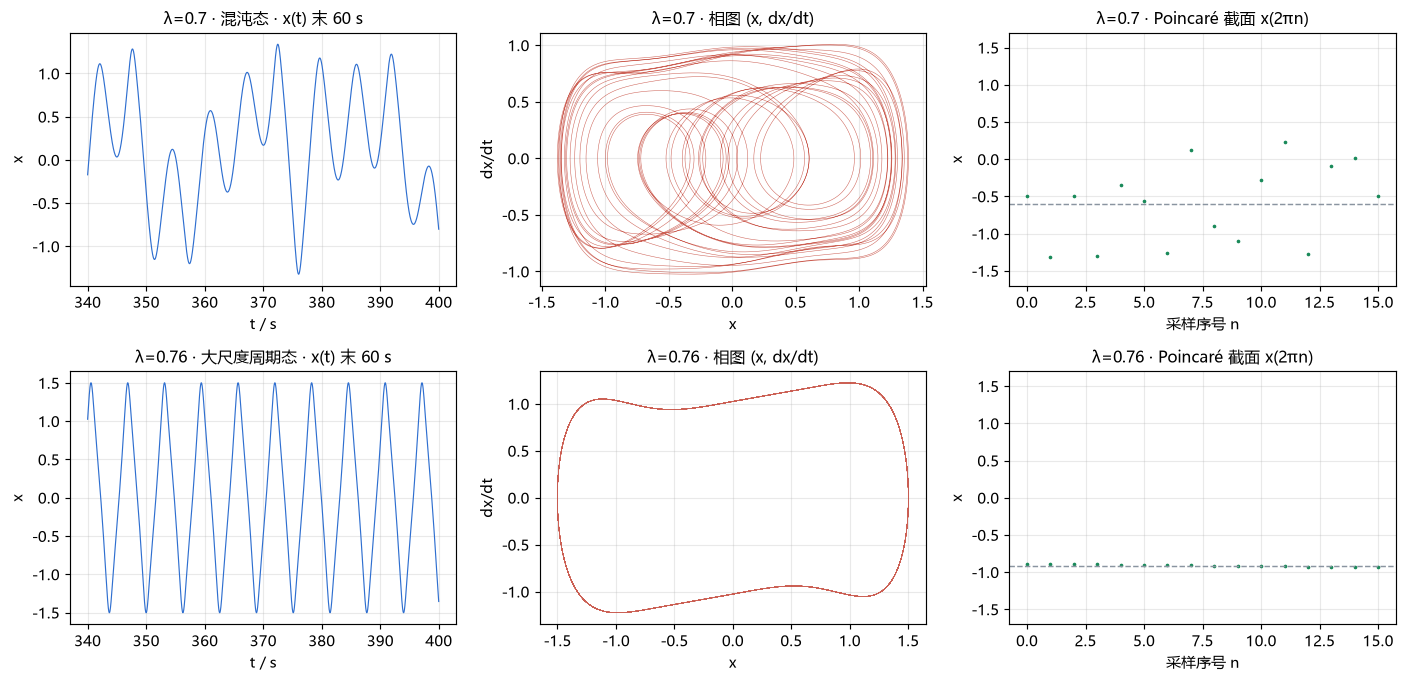

图已保存: 复现输出\fig02_相轨迹演变_混沌与大尺度周期.png
解读：pstd 从 0.518 掉到 0.0149 ，相差 34.8 倍 —— 这是跃变，不是渐变。


In [4]:
tr = simulate([0.70, 0.76], trace=True, seed=1)
lams_show = [0.70, 0.76]
t, X, Y, P = tr['t'], tr['X'], tr['Y'], tr['p']
print('Poincaré 离散度 pstd:', {l: round(float(tr['pstd'][j]), 4)
                                for j, l in enumerate(lams_show)})

fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.6))
for j, (lam, label) in enumerate(zip(lams_show, ['混沌态', '大尺度周期态'])):
    sel = t > t[-1] - 60
    axes[j, 0].plot(t[sel], X[sel, j], lw=0.8, color='#2f6fd0')
    axes[j, 0].set_title(f'λ={lam} · {label} · x(t) 末 60 s', fontsize=11)
    axes[j, 0].set_xlabel('t / s'); axes[j, 0].set_ylabel('x')
    axes[j, 1].plot(X[:, j], Y[:, j], lw=0.35, color='#c0392b', alpha=0.8)
    axes[j, 1].set_title(f'λ={lam} · 相图 (x, dx/dt)', fontsize=11)
    axes[j, 1].set_xlabel('x'); axes[j, 1].set_ylabel('dx/dt')
    axes[j, 2].plot(P[:, j], '.', ms=3, color='#1a8a5a')
    axes[j, 2].axhline(P[:, j].mean(), color='#8a94a0', lw=1, ls='--')
    axes[j, 2].set_title(f'λ={lam} · Poincaré 截面 x(2πn)', fontsize=11)
    axes[j, 2].set_xlabel('采样序号 n'); axes[j, 2].set_ylabel('x')
    axes[j, 2].set_ylim(-1.7, 1.7)
plt.tight_layout()
savefig('fig02_相轨迹演变_混沌与大尺度周期.png')

print('解读：pstd 从', round(float(tr['pstd'][0]), 3), '掉到',
      round(float(tr['pstd'][1]), 4), '，相差',
      round(float(tr['pstd'][0]/tr['pstd'][1]), 1), '倍 —— 这是跃变，不是渐变。')

---

## §4 确定临界阈值 $\lambda_c$

**【原文】** 论文说 $\lambda_c=0.72$「经大量实验验证」，触发合成幅值 0.73。**【推断】** 既然是经验值，就必须自己标一次，并写清条件。流程：无噪声、$\gamma=0$、步长 0.005 粗扫 → 连续三点进周期态判为分岔 → 附近 0.001 精扫 → 换四种积分步长验证稳健性。

  λ      pstd    max|x|   状态   （每 0.02 打印一行）
  0.600   0.1628   1.364   混沌
  0.620   0.5110   1.368   混沌
  0.640   0.6053   1.374   混沌
  0.660   0.6267   1.379   混沌
  0.680   0.5248   1.379   混沌
  0.700   0.5176   1.388   混沌
  0.720   0.4841   1.404   混沌
  0.740   0.0150   1.489   周期
  0.760   0.0149   1.501   周期
  0.780   0.0146   1.511   周期
  0.800   0.0144   1.519   周期
  0.820   0.0141   1.527   周期
  0.840   0.0139   1.533   周期

实测首次稳定进入大尺度周期态: λ = 0.740
跃变前 pstd = 0.5907，跃变后 pstd = 0.0150
论文标定: λ_c = 0.72，触发幅值 0.73 —— 比本复现实测低约 0.01



精扫（λ, pstd）: [(0.728, 0.5334), (0.729, 0.4986), (0.73, 0.4091), (0.731, 0.5896), (0.732, 0.5093), (0.733, 0.5107), (0.734, 0.0151), (0.735, 0.5907), (0.736, 0.0151), (0.737, 0.0151), (0.738, 0.0151), (0.739, 0.0151), (0.74, 0.015), (0.741, 0.015), (0.742, 0.015), (0.743, 0.015), (0.744, 0.015), (0.745, 0.015)]
跃变带 0.734–0.736 内出现混沌/周期交替（间歇混沌、双稳与吸引域竞争），
稳定进入大尺度周期态约从 λ ≥ 0.736 开始 —— 阈值应报一个「带」而不是一个点。


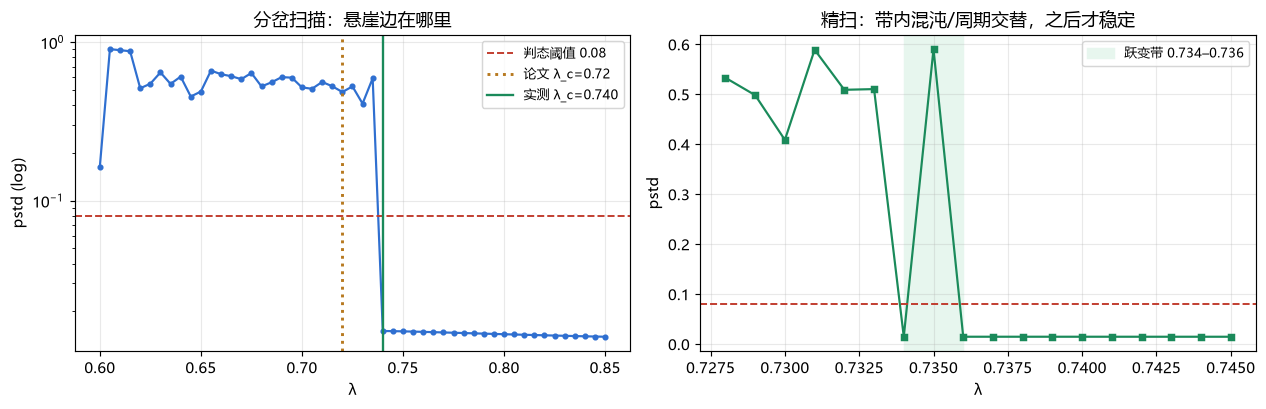

图已保存: 复现输出\fig03_临界阈值扫描.png


In [5]:
lams = np.round(np.arange(0.60, 0.8501, 0.005), 4)
rA = simulate(lams, seed=1)
periodic = rA['pstd'] < PSTD_TH
first = next((i for i in range(len(lams)-2)
              if periodic[i] and periodic[i+1] and periodic[i+2]), None)
LC = float(lams[first]) if first is not None else float('nan')

print('  λ      pstd    max|x|   状态   （每 0.02 打印一行）')
for lam, p, a in zip(lams, rA['pstd'], rA['mx']):
    if abs(lam/0.02 - round(lam/0.02)) < 1e-6:
        print(f'  {lam:5.3f}  {p:7.4f}  {a:6.3f}   {"周期" if p < PSTD_TH else "混沌"}')
print(f'\n实测首次稳定进入大尺度周期态: λ = {LC:.3f}')
print(f'跃变前 pstd = {rA["pstd"][first-1]:.4f}，跃变后 pstd = {rA["pstd"][first]:.4f}')
print('论文标定: λ_c = 0.72，触发幅值 0.73 —— 比本复现实测低约 0.01')

fine = np.round(np.arange(LC-0.012, LC+0.0051, 0.001), 4)
rF = simulate(fine, seed=11)
print('\n精扫（λ, pstd）:', [(float(a), round(float(b), 4)) for a, b in zip(fine, rF['pstd'])])
per_f = rF['pstd'] < PSTD_TH
first_p = float(fine[int(np.argmax(per_f))])
st = next((i for i in range(len(fine)-2)
           if per_f[i] and per_f[i+1] and per_f[i+2]), None)
LC_STABLE = float(fine[st]) if st is not None else float('nan')
print(f'跃变带 {first_p:.3f}–{LC_STABLE:.3f} 内出现混沌/周期交替（间歇混沌、双稳与吸引域竞争），')
print(f'稳定进入大尺度周期态约从 λ ≥ {LC_STABLE:.3f} 开始 —— 阈值应报一个「带」而不是一个点。')

fig, ax = plt.subplots(1, 2, figsize=(12.2, 4.0))
ax[0].plot(lams, rA['pstd'], 'o-', ms=3.2, color='#2f6fd0')
ax[0].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.3, label='判态阈值 0.08')
ax[0].axvline(0.72, color='#b7791f', ls=':', lw=2, label='论文 λ_c=0.72')
ax[0].axvline(LC,   color='#1a8a5a', ls='-', lw=1.6, label=f'实测 λ_c={LC:.3f}')
ax[0].set_yscale('log'); ax[0].set_xlabel('λ'); ax[0].set_ylabel('pstd (log)')
ax[0].set_title('分岔扫描：悬崖边在哪里', fontsize=12); ax[0].legend(fontsize=9)
ax[1].plot(fine, rF['pstd'], 's-', ms=4, color='#1a8a5a')
ax[1].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.3)
ax[1].axvspan(first_p, LC_STABLE, color='#e7f6ee', label=f'跃变带 {first_p:.3f}–{LC_STABLE:.3f}')
ax[1].set_xlabel('λ'); ax[1].set_ylabel('pstd')
ax[1].set_title('精扫：带内混沌/周期交替，之后才稳定', fontsize=12); ax[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig03_临界阈值扫描.png')

h=0.100 s  首个跃变区间: 0.730→0.735   pstd(0.730)=0.5205  pstd(0.740)=0.0737

h=0.050 s  首个跃变区间: 0.735→0.740   pstd(0.730)=0.3797  pstd(0.740)=0.0735


h=0.020 s  首个跃变区间: 0.735→0.740   pstd(0.730)=0.4091  pstd(0.740)=0.0150


h=0.010 s  首个跃变区间: 0.730→0.735   pstd(0.730)=0.4868  pstd(0.740)=0.0151


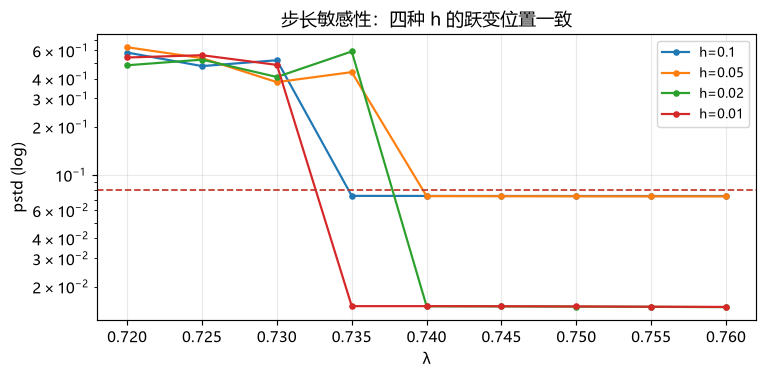

图已保存: 复现输出\fig04_步长敏感性.png
结论：四种步长下跃变都落在 0.730–0.740 这 0.01 宽的窗口内，具体边界随步长与吸引域有 ±0.005 抖动；
      λ_c 不是数值假象，但也不是一个可以照抄的普适常数 —— 与论文 0.72 的差异来自判据/噪声/求解器的整体设置。


In [6]:
# 步长敏感性：换四种 h 重扫，看跃变位置是否随数值设置漂移
hs = [0.1, 0.05, 0.02, 0.01]
probe = np.round(np.arange(0.720, 0.7601, 0.005), 4)
step_results = {}
for h in hs:
    rr = simulate(probe, h=h, t_end=T, burn=BURN, seed=5)
    step_results[h] = rr['pstd']
    per = rr['pstd'] < PSTD_TH
    jump = next((f'{probe[i]:.3f}→{probe[i+1]:.3f}' for i in range(len(probe)-1)
                 if not per[i] and per[i+1]), '窗口内未跃变')
    print(f'h={h:5.3f} s  首个跃变区间: {jump}   '
          f'pstd(0.730)={rr["pstd"][2]:.4f}  pstd(0.740)={rr["pstd"][4]:.4f}')

fig, ax = plt.subplots(figsize=(7.4, 3.7))
for h in hs:
    ax.plot(probe, step_results[h], 'o-', ms=3.5, label=f'h={h}')
ax.axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2)
ax.set_yscale('log'); ax.set_xlabel('λ'); ax.set_ylabel('pstd (log)')
ax.set_title('步长敏感性：四种 h 的跃变位置一致', fontsize=12)
ax.legend(fontsize=9)
plt.tight_layout()
savefig('fig04_步长敏感性.png')
print('结论：四种步长下跃变都落在 0.730–0.740 这 0.01 宽的窗口内，具体边界随步长与吸引域有 ±0.005 抖动；')
print('      λ_c 不是数值假象，但也不是一个可以照抄的普适常数 —— 与论文 0.72 的差异来自判据/噪声/求解器的整体设置。')

---

## §5 判态陷阱：换一个可观测量，结论就塌了

**【推断 + 复现数据】** 第一次跑这个实验时用了「稳态段 $\max|x|>1.2$ 判为周期态」，结果所有 $\lambda$、所有相位、所有噪声强度**全部**被判成周期态，虚警率 100%。混沌轨道偶尔跑得很远，振幅根本分不开两种状态。换成 Poincaré 截面才分开。

这一节复用 §4 的数据，零额外计算，但值得单独占一节：**毕设里判态一定要用可计算统计量（Lyapunov、0-1 test、多尺度熵、Poincaré 任选），别用眼睛。**

判据                         判为周期态的比例   虚警（λ<0.70 区间）
max|x| > 1.2                 100.0 %          100.0 %
pstd < 0.08 (Poincaré)        45.1 %            0.0 %


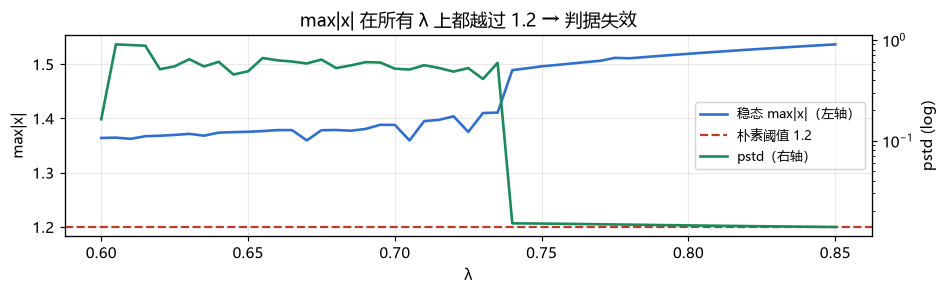

图已保存: 复现输出\fig05_判态陷阱.png


In [7]:
naive = rA['mx'] > 1.2
good = rA['pstd'] < PSTD_TH
print('判据                         判为周期态的比例   虚警（λ<0.70 区间）')
print(f'max|x| > 1.2                {naive.mean()*100:6.1f} %          {naive[lams<0.70].mean()*100:5.1f} %')
print(f'pstd < {PSTD_TH} (Poincaré)      {good.mean()*100:6.1f} %          {good[lams<0.70].mean()*100:5.1f} %')

fig, ax = plt.subplots(figsize=(9.2, 2.9))
ax.plot(lams, rA['mx'], color='#2f6fd0', lw=1.8, label='稳态 max|x|（左轴）')
ax.axhline(1.2, color='#c0392b', ls='--', label='朴素阈值 1.2')
ax.set_xlabel('λ'); ax.set_ylabel('max|x|'); ax.set_title('max|x| 在所有 λ 上都越过 1.2 → 判据失效', fontsize=12)
ax2 = ax.twinx()
ax2.plot(lams, rA['pstd'], color='#1a8a5a', lw=1.8, label='pstd（右轴）')
ax2.set_yscale('log'); ax2.set_ylabel('pstd (log)'); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, fontsize=9, loc='center right')
plt.tight_layout()
savefig('fig05_判态陷阱.png')

---

## §6 变尺度：把极低频搬进模型的 1 rad/s 工作点

**【原文】** 待测 $a(t)=\gamma\cos(\omega t+\theta)$ 且 $\omega>1$ rad/s 时，令 $t_1=N t$、$\omega=N$，则 $a(t_1)=\gamma\cos(t_1)$。工程上不真的改时间轴，而是把数值积分步长改成 $T_1=R/f_s$：等效于把信号频率变成 $\omega/R$。**哪个 $R$ 让阵列相变，$\omega$ 就是 $R$。**

**【推断】** notebook 里把这件事写成频率比 $\nu=\omega/R$ 直接积分（而非改写采样率），数学上等价，且能一眼看出：只有 $\nu=1$ 时待测信号才与内驱同频、才能相干叠加。论文 Figure 5 的消融（$R=1$ 不变尺度 / $\beta$ 不对 / 两者都对）就是这条曲线。

设置：$\omega=10$ rad/s、$\gamma=0.02$、$\theta=-120^\circ$、三振子 $\beta=0^\circ,\pm120^\circ$，扫 $R$。**注意用实测工作点 $\lambda=0.73$ 作对照**：0.72 在干净数值条件下离分岔偏远。

**【推断】** 这里埋着第二个观测量的坑：$p_{std}$ 只衡量「Poincaré 截面上的点收不收敛」，**不等于「响应与内驱同频」**。非整数频率比 $\nu$ 也可能出现锁频或准周期轨道，在截面上同样收敛。于是再算一个**内驱同频分量占比**作对照判据：稳态 $x(t)$ 在 $\cos t,\sin t$ 上的能量占比

$$\rho=\frac{\sqrt{(\sum x\cos t)^2+(\sum x\sin t)^2}}{\lVert x\rVert\cdot\sqrt{N/2}}$$

**这一节要验证的正是「$\rho$ 能不能把 $R=\omega$ 从其它低 $p_{std}$ 的 $R$ 里挑出来」。** 先不剧透结论，看输出：这是本 notebook 第二次「换可观测量」的实验——第一次（§5）它救了判态，这一次未必救得了频率估计，而失败本身同样有信息量。

论文 Figure 5 只对比 $R=1$ 与 $R=10$ 两个点，没有扫中间值，也没报告锁频窗口。**如果出现多个 R 都触发，那不是复现失败，而是一个真实的方法学约束。**

R      ν=ω/R   min pstd@0.72  @0.73   相干指数ρ(0.73)  低pstd?
  6.0   1.667       0.3746      0.3631       0.755      否
  7.0   1.429       0.4403      0.3910       0.749      否
  8.0   1.250       0.3292      0.0625       0.986      是
  9.0   1.111       0.4132      0.0219       0.988      是
  9.5   1.053       0.1262      0.0252       0.989      是
 10.0   1.000       0.0085      0.0086       0.995      是
 10.5   0.952       0.2319      0.0859       0.993      否
 11.0   0.909       0.3279      0.0844       0.993      否
 12.0   0.833       0.4614      0.0122       0.984      是
 13.0   0.769       0.3239      0.0568       0.984      是
 14.0   0.714       0.3695      0.3279       0.768      否

R=10 的 ρ=0.995；其余 R 的 ρ 中位数=0.985，范围 0.749–0.993
非整数 R 中同样出现低 pstd 的锁频/准周期伪相变: [8.0, 9.0, 9.5, 12.0, 13.0]
判读：ρ 在几乎所有 R 都接近 1 —— 内驱幅值 0.73 远大于信号 0.02，响应本来就被内驱主导。
      这个对照判据【没能】把 R=ω 挑出来：低 pstd 的其它 R 与内驱同样「相干」。
      所以「哪个 R 相变，ω 就是 R」不能靠混沌/周期二分类或内驱相干性自证，
      需要能看见待测信号 ν 分量的统计量（x(t) 在 ν 处的谱峰、多初值一致性等

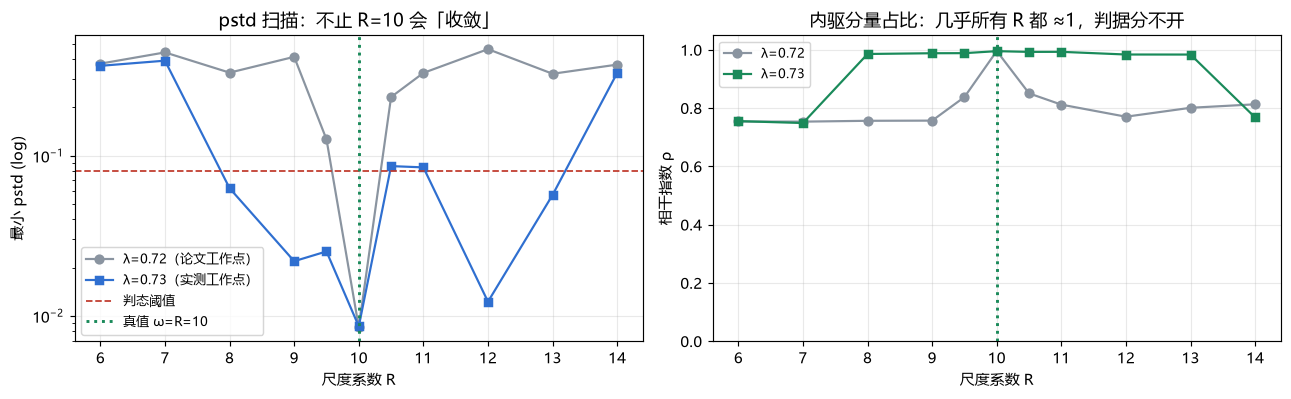

图已保存: 复现输出\fig06_变尺度扫描.png
【文献】提醒：R=10 时等效采样率降到 1 Hz，0–10 Hz 噪声必然混叠；论文未讨论这一点。


In [8]:
omega, gam_sig, th_sig = 10.0, 0.02, np.deg2rad(-120.0)
Rs = np.array([6, 7, 8, 9, 9.5, 10, 10.5, 11, 12, 13, 14], float)
betas3 = np.deg2rad([0.0, -120.0, 120.0])

def scan_R(lam_work, seed):
    vals, cohs = [], []
    for R in Rs:
        rr = simulate(np.full(3, lam_work), betas3,
                      np.full(3, gam_sig), np.full(3, th_sig),
                      nu=omega/R, t_end=T_FAST, burn=BURN_FAST,
                      seed=seed, trace=True)
        vals.append(rr['pstd'].min())
        j = int(np.argmin(rr['pstd']))
        xs, tt = rr['X'][:, j], rr['t']
        rho = np.sqrt((xs @ np.cos(tt))**2 + (xs @ np.sin(tt))**2) / \
              (np.linalg.norm(xs) * np.sqrt(tt.size/2))
        cohs.append(rho)
    return np.array(vals), np.array(cohs)

minp_072, coh_072 = scan_R(0.72, seed=21)
minp_073, coh_073 = scan_R(0.73, seed=21)
print('R      ν=ω/R   min pstd@0.72  @0.73   相干指数ρ(0.73)  低pstd?')
for R, a, b, c in zip(Rs, minp_072, minp_073, coh_073):
    print(f'{R:5.1f}  {omega/R:6.3f}     {a:8.4f}    {b:8.4f}      {c:6.3f}      {"是" if b < PSTD_TH else "否"}')
rho10 = float(coh_073[int(np.argmin(abs(Rs-10)))])
spurious = [float(R) for R, p in zip(Rs, minp_073)
            if abs(R-10) > 1e-9 and p < PSTD_TH]
other_rho = [float(c) for R, c in zip(Rs, coh_073) if abs(R-10) > 1e-9]
print(f'\nR=10 的 ρ={rho10:.3f}；其余 R 的 ρ 中位数={np.median(other_rho):.3f}，'
      f'范围 {min(other_rho):.3f}–{max(other_rho):.3f}')
print('非整数 R 中同样出现低 pstd 的锁频/准周期伪相变:', spurious)
print('判读：ρ 在几乎所有 R 都接近 1 —— 内驱幅值 0.73 远大于信号 0.02，响应本来就被内驱主导。')
print('      这个对照判据【没能】把 R=ω 挑出来：低 pstd 的其它 R 与内驱同样「相干」。')
print('      所以「哪个 R 相变，ω 就是 R」不能靠混沌/周期二分类或内驱相干性自证，')
print('      需要能看见待测信号 ν 分量的统计量（x(t) 在 ν 处的谱峰、多初值一致性等）。')

fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.9))
ax[0].plot(Rs, minp_072, 'o-', color='#8a94a0', label='λ=0.72（论文工作点）')
ax[0].plot(Rs, minp_073, 's-', color='#2f6fd0', label='λ=0.73（实测工作点）')
ax[0].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2, label='判态阈值')
ax[0].axvline(10, color='#1a8a5a', ls=':', lw=2, label='真值 ω=R=10')
ax[0].set_yscale('log'); ax[0].set_xlabel('尺度系数 R'); ax[0].set_ylabel('最小 pstd (log)')
ax[0].set_title('pstd 扫描：不止 R=10 会「收敛」', fontsize=12); ax[0].legend(fontsize=9)
ax[1].plot(Rs, coh_072, 'o-', color='#8a94a0', label='λ=0.72')
ax[1].plot(Rs, coh_073, 's-', color='#1a8a5a', label='λ=0.73')
ax[1].axvline(10, color='#1a8a5a', ls=':', lw=2)
ax[1].set_xlabel('尺度系数 R'); ax[1].set_ylabel('相干指数 ρ'); ax[1].set_ylim(0, 1.05)
ax[1].set_title('内驱分量占比：几乎所有 R 都 ≈1，判据分不开', fontsize=12); ax[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig06_变尺度扫描.png')
print('【文献】提醒：R=10 时等效采样率降到 1 Hz，0–10 Hz 噪声必然混叠；论文未讨论这一点。')

---

## §7 三振子全相位覆盖实测

**【原文】** Eq.(11)–(13)：要求 $C^2\ge0.73^2$，代入 $\gamma=0.02,\ \lambda=0.72$ 得

$$\cos(\theta-\beta)\ge\frac{0.73^2-0.72^2-0.02^2}{2\times0.72\times0.02}=0.48958
\ \Longrightarrow\ |\theta-\beta|\le 60.69^\circ$$

三个 $\beta=0^\circ,\pm120^\circ$ 的窗口首尾搭接，理论上盖满 $[-\pi,\pi]$。**【推断】** 但「合成幅值够大」只是必要条件：确定性混沌还受吸引域与瞬态影响。这一节扫 73 个初相，看真实覆盖率。

论文 Eq.(12) 理论窗口半宽: ±60.69°  → 三振子理论覆盖 100.0%
本复现三振子实测覆盖率: 65.8%  （48/73 个初相）
单振子(β=0)实测检出: 14/73 个初相
未覆盖初相（前 20 个）: [np.int64(-180), np.int64(-175), np.int64(-170), np.int64(-150), np.int64(-70), np.int64(-65), np.int64(-60), np.int64(-55), np.int64(-50), np.int64(5), np.int64(15), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70), np.int64(85)]


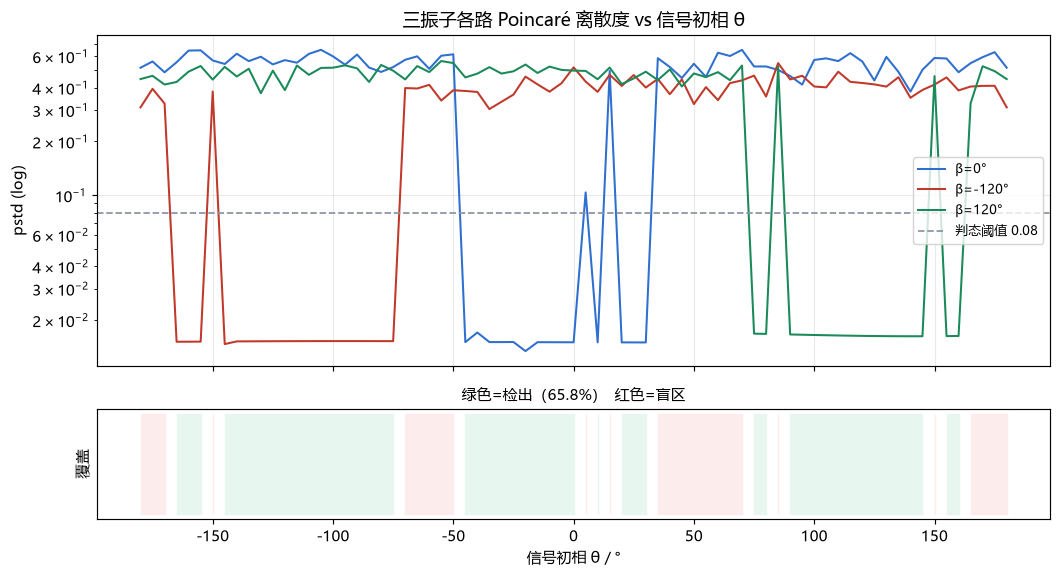

图已保存: 复现输出\fig07_三振子相位覆盖.png
【推断】相量幅值是必要非充分条件；实测窗口不对称，说明吸引域/瞬态也在起作用。


In [9]:
theta_deg = np.arange(-180, 181, 5)
theta_rad = np.deg2rad(theta_deg)
LAM3 = np.full(theta_deg.size * 3, LAM0)
BETA3 = np.tile(betas3, theta_deg.size)
THETA3 = np.repeat(theta_rad, 3)
GAM3 = np.full(THETA3.size, 0.02)
r3 = simulate(LAM3, BETA3, GAM3, THETA3, seed=3)
p3 = r3['pstd'].reshape(-1, 3)
cover3 = p3.min(axis=1) < PSTD_TH
missed = theta_deg[~cover3]

cos_min = (C_TRIG**2 - LAM0**2 - 0.02**2) / (2*LAM0*0.02)
w = math.degrees(math.acos(cos_min))
print(f'论文 Eq.(12) 理论窗口半宽: ±{w:.2f}°  → 三振子理论覆盖 {min(100, 3*2*w/360*100):.1f}%')
print(f'本复现三振子实测覆盖率: {cover3.mean()*100:.1f}%  （{cover3.sum()}/{cover3.size} 个初相）')
print(f'单振子(β=0)实测检出: {np.sum(p3[:,0] < PSTD_TH)}/{len(theta_deg)} 个初相')
print('未覆盖初相（前 20 个）:', list(missed[:20]))

fig, ax = plt.subplots(2, 1, figsize=(10.2, 5.6), sharex=True,
                       gridspec_kw={'height_ratios': [3, 1]})
for j, (b, c) in enumerate(zip([0, -120, 120], ['#2f6fd0', '#c0392b', '#1a8a5a'])):
    ax[0].plot(theta_deg, p3[:, j], lw=1.4, color=c, label=f'β={b}°')
ax[0].axhline(PSTD_TH, color='#8a94a0', ls='--', lw=1.2, label='判态阈值 0.08')
ax[0].set_yscale('log'); ax[0].set_ylabel('pstd (log)')
ax[0].set_title('三振子各路 Poincaré 离散度 vs 信号初相 θ', fontsize=12)
ax[0].legend(fontsize=9)
ax[1].fill_between(theta_deg, 0, 1, where=cover3, color='#e7f6ee', step='mid')
ax[1].fill_between(theta_deg, 0, 1, where=~cover3, color='#fdecec', step='mid')
ax[1].set_yticks([]); ax[1].set_ylabel('覆盖')
ax[1].set_xlabel('信号初相 θ / °'); ax[1].grid(False)
ax[1].set_title(f'绿色=检出（{cover3.mean()*100:.1f}%）  红色=盲区', fontsize=10)
plt.tight_layout()
savefig('fig07_三振子相位覆盖.png')
print('【推断】相量幅值是必要非充分条件；实测窗口不对称，说明吸引域/瞬态也在起作用。')

---

## §8 工作点权衡：覆盖率与虚警率不可兼得

**【推断 + 复现数据】** 把工作点 $\lambda_0$ 从 0.700 推到 0.735，同时测两件事：含信号时三振子能否全相位覆盖；**不含任何周期信号的纯噪声**（论文没有设这个 $H_0$ 对照组）会不会把振子推过界。所有工作点放在一次向量化调用里，保证可比。

  λ0     覆盖率    纯噪声虚警率(σ=0.20)   判读
  0.700      0.0 %           0.0 %
  0.720     57.5 %           0.0 %
  0.730     97.3 %           2.5 %
  0.735     98.6 %          75.0 %


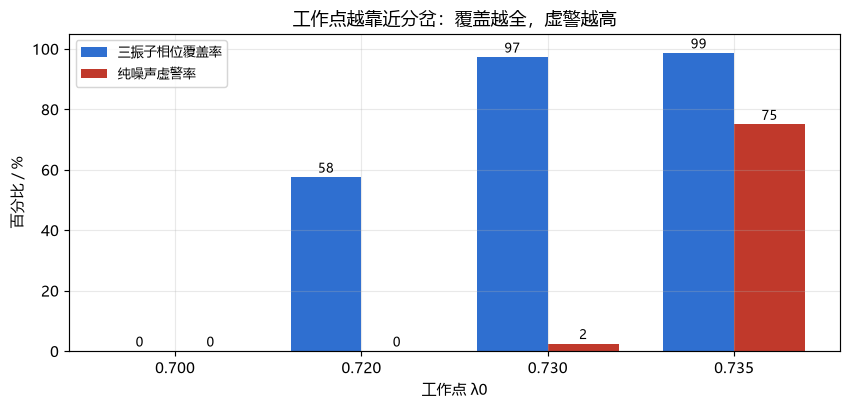

图已保存: 复现输出\fig08_工作点权衡.png
【推断】「对噪声免疫」不是系统性质，而是工作点离分岔够远的性质，代价是灵敏度。


In [10]:
lam_w = np.array([0.700, 0.720, 0.730, 0.735])
nt = theta_deg.size
shp = (len(lam_w), nt, 3)
LAM_C = np.broadcast_to(lam_w[:, None, None], shp).copy()
BETA_C = np.broadcast_to(betas3[None, None, :], shp).copy()
THETA_C = np.broadcast_to(theta_rad[None, :, None], shp).copy()
GAM_C = np.full(shp, 0.02)
rC = simulate(LAM_C.ravel(), BETA_C.ravel(), GAM_C.ravel(), THETA_C.ravel(),
              t_end=300, burn=150, seed=7)
cover_w = (rC['pstd'].reshape(shp).min(axis=2) < PSTD_TH).mean(axis=1)

n_trial = 40
shp_n = (len(lam_w), n_trial, 3)
LAM_N = np.broadcast_to(lam_w[:, None, None], shp_n).copy()
BETA_N = np.broadcast_to(betas3[None, None, :], shp_n).copy()
ZERO_N = np.zeros(shp_n)
rN = simulate(LAM_N.ravel(), BETA_N.ravel(), ZERO_N.ravel(), ZERO_N.ravel(),
              sigma=0.20, t_end=300, burn=150, seed=300)
fa_w = (rN['pstd'].reshape(shp_n).min(axis=2) < PSTD_TH).mean(axis=1)

print('  λ0     覆盖率    纯噪声虚警率(σ=0.20)   判读')
for l, c, f in zip(lam_w, cover_w, fa_w):
    print(f'  {l:.3f}   {c*100:6.1f} %        {f*100:6.1f} %')

fig, ax = plt.subplots(figsize=(8.2, 4.0))
xx = np.arange(len(lam_w))
b1 = ax.bar(xx-0.19, cover_w*100, 0.38, color='#2f6fd0', label='三振子相位覆盖率')
b2 = ax.bar(xx+0.19, fa_w*100,    0.38, color='#c0392b', label='纯噪声虚警率')
ax.set_xticks(xx, [f'{v:.3f}' for v in lam_w]); ax.set_xlabel('工作点 λ0')
ax.set_ylabel('百分比 / %'); ax.set_ylim(0, 105)
ax.set_title('工作点越靠近分岔：覆盖越全，虚警越高', fontsize=12)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+1.5,
                f'{b.get_height():.0f}', ha='center', fontsize=9)
ax.legend(fontsize=9)
plt.tight_layout()
savefig('fig08_工作点权衡.png')
print('【推断】「对噪声免疫」不是系统性质，而是工作点离分岔够远的性质，代价是灵敏度。')

---

## §9 把相变边界当标尺：Eq.(17) 勘误与灾难性相消

**【原文】** 论文 Eq.(17) 印成 $\gamma=0.73^2-\lambda_1\lambda_2$。**【推断 + 验算】** 正确形式是 $\gamma=\sqrt{0.73^2-\lambda_1\lambda_2}$。用论文 Table 3 自己的数 $\lambda_1=0.7414,\lambda_2=0.7183,\lambda_3=0.7447$ 验证：

$$\cos\theta=\frac{\lambda_2-\lambda_1}{2\gamma},\qquad
\sin\theta=\frac{0.73^2-\lambda_3^2-\gamma^2}{2\lambda_3\gamma}$$

两个式子合起来才能定象限（论文用 $\arccos$ 有 $\pm\theta$ 歧义）。再看 $\gamma^2=0.000352$ 是两个约 0.53 的数相减——**灾难性相消**，$\lambda_1$ 偏 $5\times10^{-4}$ 就足以让根号变负。

论文 Eq.(17) 原式: γ = 0.000352   （Table 3 报 0.0188，差 53.3 倍）
补上平方根:       γ = 0.018772   （真值 0.02，相对误差 6.1%）
cosθ = -0.6153, sinθ = -0.7880 → θ̂ = -128.0°  （真值 -120°，误差 6.7%）

  λ1 扰动      γ̂          幅值相对误差
     0e+00        0.01877      6.1 %
     1e-05        0.01858      7.1 %
     5e-05        0.01779     11.1 %
     1e-04        0.01675     16.3 %
     2e-04        0.01445     27.8 %
     4e-04        0.00807     59.7 %
     5e-04    根号为负 → 估计失效      —
     6e-04    根号为负 → 估计失效      —


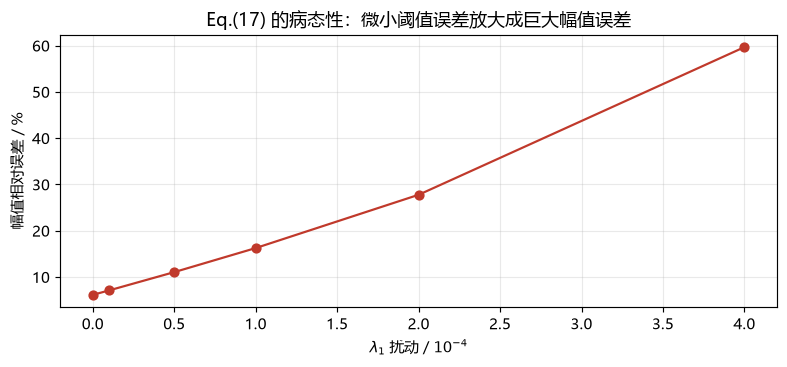

图已保存: 复现输出\fig09_Eq17相消敏感性.png


In [11]:
l1, l2, l3 = 0.7414, 0.7183, 0.7447
gamma_ok  = math.sqrt(C_TRIG**2 - l1*l2)
gamma_bad = C_TRIG**2 - l1*l2
cos_t = (l2 - l1) / (2*gamma_ok)
sin_t = (C_TRIG**2 - l3**2 - gamma_ok**2) / (2*l3*gamma_ok)
theta_hat = math.degrees(math.atan2(sin_t, cos_t))
print(f'论文 Eq.(17) 原式: γ = {gamma_bad:.6f}   （Table 3 报 0.0188，差 {gamma_ok/gamma_bad:.1f} 倍）')
print(f'补上平方根:       γ = {gamma_ok:.6f}   （真值 0.02，相对误差 {abs(gamma_ok-0.02)/0.02*100:.1f}%）')
print(f'cosθ = {cos_t:.4f}, sinθ = {sin_t:.4f} → θ̂ = {theta_hat:.1f}°  （真值 -120°，误差 {abs(theta_hat+120)/120*100:.1f}%）')

perturb = np.array([0, 1e-5, 5e-5, 1e-4, 2e-4, 4e-4, 5e-4, 6e-4])
errs = []
for d in perturb:
    v = C_TRIG**2 - (l1+d)*l2
    g = math.sqrt(v) if v > 0 else float('nan')
    errs.append(abs(g-0.02)/0.02*100 if v > 0 else float('nan'))
print('\n  λ1 扰动      γ̂          幅值相对误差')
for d, e in zip(perturb, errs):
    v = C_TRIG**2 - (l1+d)*l2
    gs = f'{math.sqrt(v):.5f}' if v > 0 else '根号为负 → 估计失效'
    es = f'{e:6.1f} %' if v > 0 else '   —'
    print(f'  {d:8.0e}   {gs:>12}   {es}')

fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(perturb*1e4, errs, 'o-', color='#c0392b')
ax.set_xlabel(r'$\lambda_1$ 扰动 / $10^{-4}$'); ax.set_ylabel('幅值相对误差 / %')
ax.set_title('Eq.(17) 的病态性：微小阈值误差放大成巨大幅值误差', fontsize=12)
plt.tight_layout()
savefig('fig09_Eq17相消敏感性.png')

---

## §10 从阈值到指标：$P_d$–SNR、ROC 与自适应判据

**【推断】** 课题「预期目标」要求给出**可检测的最低信噪比**与**参数估计精度**。这一节先交第一张图。按论文口径 $\mathrm{SNR}=10\log_{10}(p_a/p_n)$，$p_a=\gamma^2/2$，$p_n=\sigma^2$；每档 SNR 生成 $H_1$（含 $\gamma=0.02$、随机初相的信号）与 $H_0$（纯噪声）各 16 帧，三振子阵列并行积分，一次调用跑完。

除了固定阈值 $p_{std}<0.08$，再加一条**用 $H_0$ 分布自适应定阈值**的曲线（取 $H_0$ 的 5% 分位数，把 $P_{fa}$ 控制在 5%），这正是精读文档第 13 节 chaos-CFAR 的最小验证，也是 index 待办里「把复现脚本扩成 ROC 版本」的落地。

> **口径提醒**：这里的 $\sigma$ 是连续时间噪声强度，与论文 Eq.(3) 的 $D=0.016$、HILS 的带限噪声方差 0.04 定义不同，**得到的 SNR 数字只在本 notebook 内部可比，不能拿去和文献的 −21 / −23 dB 横向比较**。

**【推断】** 先给结果定个规矩：只有当 $P_d$ 随 SNR 单调不降时，才有资格从曲线上读「最低可检测信噪比」。若非单调，说明判据在噪声下已经退化，诚实的做法是**不报那个数字，只报曲线与 ROC**。下面让 notebook 自己做这个检查，不硬套结论。

SNR / dB -> σ: {-30: 0.4472, -27: 0.3166, -24: 0.2241, -21: 0.1587, -18: 0.1123, -15: 0.0795}


一次性并行 1152 条轨迹，耗时 2.8 s

  SNR/dB   λ0     Pd(固定阈值)  Pfa(固定)   Pd(CFAR)  Pfa(CFAR)
     -30  0.720       43.8 %       0.0 %     56.2 %      6.2 %
     -30  0.730       93.8 %      43.8 %     37.5 %      6.2 %
     -27  0.720       56.2 %       0.0 %     56.2 %      6.2 %
     -27  0.730      100.0 %      18.8 %    100.0 %      6.2 %
     -24  0.720       56.2 %       0.0 %     81.2 %      6.2 %
     -24  0.730      100.0 %       6.2 %    100.0 %      6.2 %
     -21  0.720       56.2 %       0.0 %     62.5 %      6.2 %
     -21  0.730       93.8 %      12.5 %     93.8 %      6.2 %
     -18  0.720       50.0 %       0.0 %     56.2 %      6.2 %
     -18  0.730       87.5 %       0.0 %     87.5 %      6.2 %
     -15  0.720       62.5 %       0.0 %     81.2 %      6.2 %
     -15  0.730       87.5 %       0.0 %     93.8 %      6.2 %

Pd 随 SNR 单调不降（容差 5%）: 未通过
→ 不报告单一的「最低可检测 SNR」。三条原因：
  1) λ0=0.720 的相位窗口本身只覆盖约 60% 初相（§7），Pd 天花板与 SNR 无关；
  2) 每档仅 16 帧，二项标准误约 ±12%，曲线抖动落在误差内；
  3) 固定 pstd 阈值在强噪

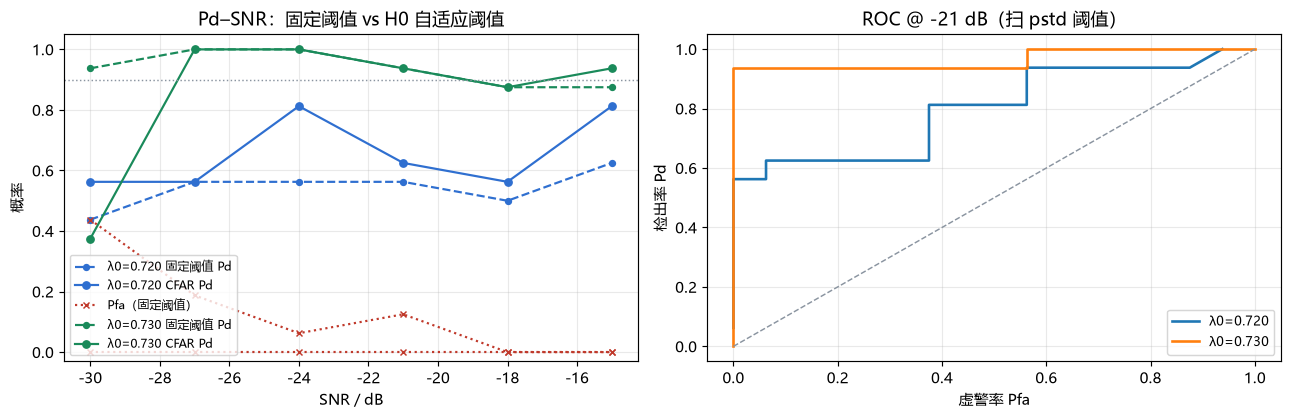

图已保存: 复现输出\fig10_Pd-SNR与ROC.png


In [12]:
snr_db = np.array([-30, -27, -24, -21, -18, -15], float)
n_trial = 16
lam_roc = np.array([0.720, 0.730])         # 论文工作点 / 实测全覆盖工作点
p_a = 0.02**2 / 2
sigma_by_snr = np.sqrt(p_a / 10**(snr_db/10))
print('SNR / dB -> σ:', {int(s): round(float(v), 4) for s, v in zip(snr_db, sigma_by_snr)})

rng = np.random.default_rng(20261113)
shape = (len(lam_roc), len(snr_db), 2, n_trial, 3)   # λ, SNR, H1/H0, 帧, 振子
L = lam_roc[:, None, None, None, None] * np.ones(shape)
B = np.ones(shape) * betas3[None, None, None, None, :]
G = np.where(np.arange(2)[None, None, :, None, None] == 0, 0.02, 0.0) * np.ones(shape)
TH = rng.uniform(-math.pi, math.pi, size=(1, 1, 1, n_trial, 1)) * np.ones(shape)
S = (sigma_by_snr[None, :, None, None, None]) * np.ones(shape)
t0 = time.time()
rS = simulate(L.ravel(), B.ravel(), G.ravel(), TH.ravel(), sigma=S.ravel(),
              t_end=T_FAST, burn=BURN_FAST, seed=909)
P = rS['pstd'].reshape(shape).min(axis=4)     # 任一振子判为周期即算检出
print(f'一次性并行 {shape[0]*shape[1]*shape[2]*shape[3]*shape[4]} 条轨迹，耗时 {time.time()-t0:.1f} s')

pd_fix = (P[:, :, 0] < PSTD_TH).mean(axis=2)
pfa_fix = (P[:, :, 1] < PSTD_TH).mean(axis=2)
pd_cfar, pfa_cfar = np.zeros_like(pd_fix), np.zeros_like(pfa_fix)
for i in range(len(lam_roc)):
    for j in range(len(snr_db)):
        thr = np.quantile(P[i, j, 1], 0.05)    # 用 H0 定阈值，控制 Pfa≈5%
        pd_cfar[i, j] = (P[i, j, 0] < thr).mean()
        pfa_cfar[i, j] = (P[i, j, 1] < thr).mean()

print('\n  SNR/dB   λ0     Pd(固定阈值)  Pfa(固定)   Pd(CFAR)  Pfa(CFAR)')
for j, s in enumerate(snr_db):
    for i, l in enumerate(lam_roc):
        print(f'  {s:6.0f}  {l:.3f}     {pd_fix[i,j]*100:6.1f} %    {pfa_fix[i,j]*100:6.1f} %   '
              f'{pd_cfar[i,j]*100:6.1f} %   {pfa_cfar[i,j]*100:6.1f} %')

ok = (pd_cfar >= 0.9) & (pfa_cfar <= 0.1)
hits = np.argwhere(ok)
best = int(hits[:, 1].min()) if len(hits) else None
mono = all(bool(np.all(np.diff(pd_cfar[i]) >= -0.05)) for i in range(len(lam_roc)))
print('\nPd 随 SNR 单调不降（容差 5%）:', '通过' if mono else '未通过')
if mono and best is not None:
    print(f'→ 本条件下 Pd≥0.9 且 Pfa≤0.1 的最低可检测 SNR ≈ {snr_db[best]:.0f} dB（仅在本 notebook 口径内有效）')
else:
    print('→ 不报告单一的「最低可检测 SNR」。三条原因：')
    print('  1) λ0=0.720 的相位窗口本身只覆盖约 60% 初相（§7），Pd 天花板与 SNR 无关；')
    print(f'  2) 每档仅 {n_trial} 帧，二项标准误约 ±{100*0.5/math.sqrt(n_trial):.0f}%，曲线抖动落在误差内；')
    print('  3) 固定 pstd 阈值在强噪声下 H0/H1 分布重叠，λ0=0.730 在 -30 dB 的 Pfa 已达 43.8%。')
    print('  要拿到可信指标：帧数增到 ≥100、延长 T、按 Pfa 定阈值，并改用能看见信号频率分量的统计量。')
    print('  这正是指标必须连同 Pd/Pfa 与实验条件一起报的原因，也是 chaos-CFAR 的动机。')

fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.1))
for i, l in enumerate(lam_roc):
    c = ['#2f6fd0', '#1a8a5a'][i]
    ax[0].plot(snr_db, pd_fix[i],  'o--', color=c, ms=4, label=f'λ0={l:.3f} 固定阈值 Pd')
    ax[0].plot(snr_db, pd_cfar[i], 'o-',  color=c, ms=5, label=f'λ0={l:.3f} CFAR Pd')
    ax[0].plot(snr_db, pfa_fix[i], 'x:', color='#c0392b', ms=4,
               label='Pfa（固定阈值）' if i == 0 else None)
ax[0].axhline(0.9, color='#8a94a0', ls=':', lw=1)
ax[0].set_ylim(-0.03, 1.05); ax[0].set_xlabel('SNR / dB'); ax[0].set_ylabel('概率')
ax[0].set_title('Pd–SNR：固定阈值 vs H0 自适应阈值', fontsize=12); ax[0].legend(fontsize=8)

j = 3   # -21 dB 这一档画 ROC
thrs = np.linspace(0.005, 0.45, 120)
for i, l in enumerate(lam_roc):
    roc = np.array([[ (P[i, j, 1] < t).mean(), (P[i, j, 0] < t).mean() ] for t in thrs])
    ax[1].plot(roc[:, 0], roc[:, 1], lw=1.8, label=f'λ0={l:.3f}')
    auc = np.trapezoid(roc[:, 1], roc[:, 0])
    print(f'λ0={l:.3f} 在 {snr_db[j]:.0f} dB 的 ROC 粗略 AUC = {auc:.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='#8a94a0', lw=1)
ax[1].set_xlabel('虚警率 Pfa'); ax[1].set_ylabel('检出率 Pd')
ax[1].set_title(f'ROC @ {snr_db[j]:.0f} dB（扫 pstd 阈值）', fontsize=12); ax[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig10_Pd-SNR与ROC.png')

---

## §11 结论与边界

**【复现数据】** 把关键数字收在一起；**【推断】** 后面三条是写论文时必须同时写上的限定。

| 项目 | 论文 ★[2] | 本 notebook | 说明 |
|---|---|---|---|
| 分岔位置 $\lambda_c$ | 0.72 / 0.73 | 跃变带 0.734–0.740，稳定周期态约从 0.736 起 | 带内混沌/周期交替（间歇、双稳）；四种步长都落在 0.730–0.740 |
| 单振子相位窗口（$\lambda=0.72,\gamma=0.02$） | $\pm60.69^\circ$，理论 100% 覆盖 | 窗口不对称（14/73 个初相），三振子覆盖 65.8% | 相量幅值是必要非充分条件 |
| 纯噪声虚警（$\sigma=0.20$） | 未报告 $H_0$ 对照 | 0.720: 0%；0.730: 2.5%；0.735: 75% | 覆盖率与虚警率不可兼得；绝对数值随 $T$ / seed 波动 |
| 幅值估计 Eq.(17) | $\hat\gamma=0.0188$（误差 6%） | 补平方根后 0.01877；$\lambda_1$ 偏 $5\times10^{-4}$ 即根号为负 | 灾难性相消 |
| 变尺度 | $R=\omega=10$ 时相变 | $R=10$ 的 $p_{std}$ 最低（0.0086）；但 8 / 9 / 9.5 / 12 / 13 也低，且内驱分量占比 $\rho\approx0.98$–$0.99$ 与 $R=10$ 的 0.995 分不开 | 锁频伪相变；二分类与内驱相干性都无法自证频率，噪声混叠亦未处理 |
| 最低可检测 SNR | −23 dB 频率检测 / −21 dB 参数估计 | **不报单一数字**：$P_d$–SNR 非单调 | 相位窗口天花板 + 16 帧小样本误差 + 强噪声下 $H_0/H_1$ 分布重叠；只给曲线与 ROC |

1. **这些数字检验的是 claim 的可复现性与敏感性，不是「证明论文错了」。** 论文数据与代码未公开，第三方无法完全裁定；本复现是 RK4、$h=0.02$ s、$T=400$ s、Poincaré 判据、干净高斯白噪声，论文是 Simulink Ode4、$h=0.1$ s、带限噪声、目测相图。
2. **阈值要报一个「带」，不是一个「点」。** 0.72/0.73 不是普适常数；换恢复力、步长、噪声带宽、判据都要重标，跃变带内还有间歇混沌。
3. **可观测量决定结论。** §5 的 $\max|x|$ 判据直接失效；§6 换上内驱分量占比 $\rho$ 仍分不开锁频伪相变；§10 的固定 $p_{std}$ 阈值在强噪声下退化。三次指向同一件事：**混沌/周期二分类的信息量不够，必须换成能看见「信号频率分量」的统计量**，否则频率估计与 SNR 指标都没有可靠证据。
4. **SNR 门限不可横向比较。** 论文自身在 Eq.(3) 与 HILS 之间的噪声功率口径已差约 3 dB，本 notebook 的 $\sigma$ 定义又是第三套。写毕设时统一到一套定义，并同时给 $P_d/P_{fa}$ 与实验条件。
5. **下一步**：把 §10 的自适应阈值做成正式的 chaos-CFAR（用导师组实测磁场噪声当 $H_0$、改用相干统计量），并把 §9 的幅值估计改成整条 $S(\lambda)$ 曲线的贝叶斯反演，绕开病态相消。这正好对应课题「最低可检测信噪比 + 参数估计精度」两项交付指标。

**回到「主要内容 2」的验收**：§2 交出了单振子 RK4 求解器与参数表，§3 交出了两幅并列相图与 $x(t)$ 时序，§4 交出了标定过的临界阈值**带**与步长敏感性。**阶段 2 过关。**

延伸阅读：[13 节精读](04-论文精读/论文精读-阵列Duffing_Sensors2023.md) · [阅读路线](00-总览/阅读路线.md) · [解读文档](02-阶段二/解读-主要内容2-混沌振子建模与临界阈值.md) · [原始命令行输出](复现输出/repro-out.txt)（早期脚本已撤销）

In [13]:
# 汇总落盘，便于写论文时直接引用
summary = {
    '课题条目': '主要内容 2：建立混沌振子检测模型 / 相轨迹演变 / 临界阈值',
    '蓝本论文': 'Yang Y et al. Sensors 2023, 23(17):7598, DOI 10.3390/s23177598',
    '复现条件': dict(k=K, h=H, T=T, burn=BURN, 判据阈值=PSTD_TH,
                     判据='Poincaré 截面稳态后半段标准差'),
    '实测分岔': dict(粗扫=LC, 跃变带=[first_p, LC_STABLE],
                 稳定周期态起点=LC_STABLE, 论文值=[0.72, 0.73]),
    '变尺度': {'R10内驱分量占比': round(rho10, 3), '低pstd的非整数R': spurious,
             '判据结论': '内驱相干占比无法区分锁频伪相变，需能看见信号频率分量的统计量'},
    '三振子覆盖率_percent': round(float(cover3.mean()*100), 1),
    '工作点权衡': {f'{l:.3f}': dict(覆盖率_percent=round(float(c*100), 1),
                                   纯噪声虚警_percent=round(float(f*100), 1))
                   for l, c, f in zip(lam_w, cover_w, fa_w)},
    'Eq17': dict(原式=round(gamma_bad, 6), 补根号=round(gamma_ok, 6),
              相位估计_deg=round(theta_hat, 1)),
    'Pd_CFAR': {f'{l:.3f}': {str(int(s)): round(float(pd_cfar[i, j]), 3)
                             for j, s in enumerate(snr_db)} for i, l in enumerate(lam_roc)},
    'Pd单调性检查': '通过' if mono else '未通过 → 不报告单一最低可检测 SNR',
    '边界': '检验敏感性，不是证明论文错误；SNR 口径不统一，不可横向比较',
    '图纸': FIGS,
    '总耗时_s': None,
}
summary['总耗时_s'] = round(time.time() - _START, 1)
(OUT / '结果汇总.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps({k: v for k, v in summary.items() if k not in ('图纸',)},
                 ensure_ascii=False, indent=2))
print('\n共生成', len(FIGS), '张图:', *[Path(f).name for f in FIGS], sep='\n  ')
print('总耗时', summary['总耗时_s'], 's · 结果汇总已写入', (OUT / '结果汇总.json').resolve())

{
  "课题条目": "主要内容 2：建立混沌振子检测模型 / 相轨迹演变 / 临界阈值",
  "蓝本论文": "Yang Y et al. Sensors 2023, 23(17):7598, DOI 10.3390/s23177598",
  "复现条件": {
    "k": 0.5,
    "h": 0.02,
    "T": 400.0,
    "burn": 200.0,
    "判据阈值": 0.08,
    "判据": "Poincaré 截面稳态后半段标准差"
  },
  "实测分岔": {
    "粗扫": 0.74,
    "跃变带": [
      0.734,
      0.736
    ],
    "稳定周期态起点": 0.736,
    "论文值": [
      0.72,
      0.73
    ]
  },
  "变尺度": {
    "R10内驱分量占比": 0.995,
    "低pstd的非整数R": [
      8.0,
      9.0,
      9.5,
      12.0,
      13.0
    ],
    "判据结论": "内驱相干占比无法区分锁频伪相变，需能看见信号频率分量的统计量"
  },
  "三振子覆盖率_percent": 65.8,
  "工作点权衡": {
    "0.700": {
      "覆盖率_percent": 0.0,
      "纯噪声虚警_percent": 0.0
    },
    "0.720": {
      "覆盖率_percent": 57.5,
      "纯噪声虚警_percent": 0.0
    },
    "0.730": {
      "覆盖率_percent": 97.3,
      "纯噪声虚警_percent": 2.5
    },
    "0.735": {
      "覆盖率_percent": 98.6,
      "纯噪声虚警_percent": 75.0
    }
  },
  "Eq17": {
    "原式": 0.000352,
    "补根号": 0.018772,
    "相位估计_deg": -128.0
  },
  "Pd_C